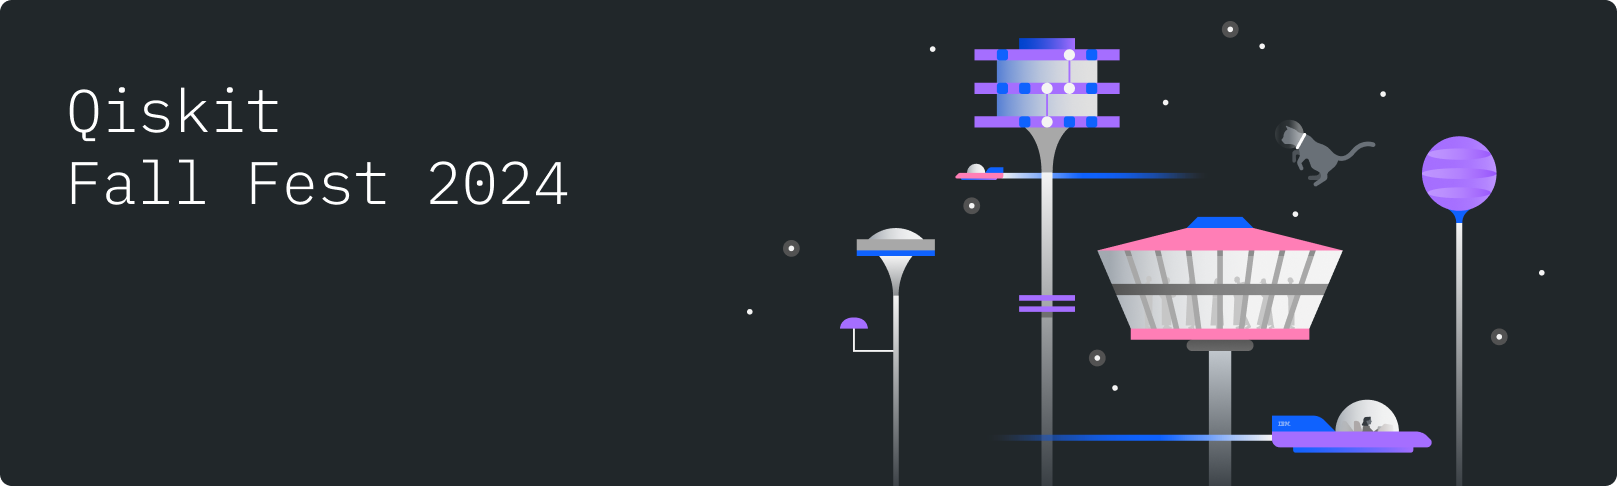

# Open Notebook 4: WORKSHOP

- TRYING TO SOLVE DISCEPRANCIES IN ENVIRONMENT
- SIMPLE HALF ADDER
- ERRORS AND NOISE
- BACKEND
RUNTIME:2 min
*(NOTE: This is an estimate only. Your runtime may vary. This does not include queue time)*

Hi there and welcome to the **Qiskit Fall Fest**!

This is notebook 4 who have to finish the "Hello World" and "Notebook_2" and "notebook_3 "before you start this notebook

## Setup
<a name="setup"></a>

From the previous notebooks try to import those things into this the flow should be
%pip install qiskit or !pip install qiskit
then all imports

In [ ]:
### Import the required packages
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

#### Save your IBM Quantum account

1.   Navigate to the [IBM Quantum Platform](https://quantum.ibm.com/) and log in
2.   Look to the top right corner, click and copy your API token (pictured above)
3.   In the code cell below, replace `Your_token_here` with your token
4.   Make sure your token is inside the quotation marks!!

In [ ]:
## Save your IBM Quantum account and set it as your default account.
QiskitRuntimeService.save_account(

    channel="ibm_quantum",

    token="EnterYourToken",

    set_as_default=True,

    # Use `overwrite=True` if you're updating your token.
    overwrite=True,
)

# Load saved credentials
service = QiskitRuntimeService()

## ERROS AND NOISE

In Qiskit, we can simulate noise to understand how our quantum circuits might behave in a real quantum computer, where noise is unavoidable. Simulating noise helps us test and optimize quantum circuits in realistic conditions, ensuring they are robust against errors.

Steps to Add Noise in Qiskit
To create artificial noise in Qiskit, we use noise models. These models simulate errors that are likely to occur in real quantum hardware. Qiskit has tools to simulate noise using the Aer simulator.

Here's an example of how to simulate noise in a quantum circuit using Qiskit:

Example of Adding Noise:

###Exercise:
Complete the circuit and run the code

In [ ]:
from qiskit import Aer, execute, QuantumCircuit
from qiskit.providers.aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error

# Create a simple quantum circuit
qc = QuantumCircuit(2)
# TRY TO REVERSE ENGINEERING WHAT GATES ARE APPLIED ON THE QUBIT
qc.measure_all()

# Build a noise model
noise_model = NoiseModel()

# Add depolarizing error to single-qubit and two-qubit gates
error_1qubit = depolarizing_error(0.01, 1)  # 1% chance of error in single-qubit gates
error_2qubit = depolarizing_error(0.02, 2)  # 2% chance of error in two-qubit gates

# Add thermal relaxation error for a single-qubit gate
error_thermal = thermal_relaxation_error(50, 50, 0.01)  # 50µs T1, T2 with 1% error probability

# Apply the errors to the noise model
noise_model.add_all_qubit_quantum_error(error_1qubit, ['u3'])  # Apply to all U3 single-qubit gates
noise_model.add_all_qubit_quantum_error(error_2qubit, ['cx'])   # Apply to CNOT gates
noise_model.add_all_qubit_quantum_error(error_thermal, ['u1'])  # Apply thermal error to U1 gates

# Get a noisy simulator backend
backend = Aer.get_backend('qasm_simulator')

# Execute the noisy quantum circuit
job = execute(qc, backend=backend, noise_model=noise_model)
result = job.result()

# Get the noisy counts (measurement results)
counts = result.get_counts()
print(counts)


##Mitigating Noise
In practice, noise is managed by:

####Quantum Error Correction (QEC):
 Special techniques like redundancy and syndrome measurement can detect and correct errors.
####Gate Optimization:
Reducing the number of gates and circuit depth can help reduce errors.
####Noise-aware Circuit Design:
Choosing algorithms that are resilient to specific types of noise or errors.

##BARRIER:
A barrier in a circuit is executed to execute  part of circuit before moving on to the next , it creates a barrier before the next circuit
####Exercise:
use barrier in your own circuit (anywhere)

In [ ]:
# Exercise 1: Implementing a circuit barrier
qc_barrier = QuantumCircuit(2, 2)
qc_barrier.h(0)
qc_barrier.barrier()  # Prevents cross-barrier gate optimization
qc_barrier.cx(0, 1)
qc_barrier.measure([0, 1], [0, 1])
qc_barrier.draw("mpl")

##EXERCISE 2 :     
Enter a logic for def a simple for half adder your job is to fill in the missing gaps in the code

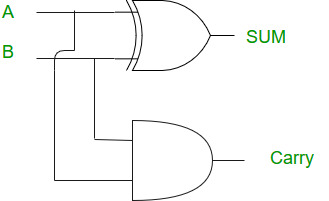

from qiskit_ibm_runtime import QiskitRuntimeService, Session, Sampler

# Initialize your service (you need an IBM Quantum account)
service = QiskitRuntimeService()

# Create a session and run a sampler
with Session(service=service, backend="ibmq_qasm_simulator") as session:
    


In [ ]:
''''sampler = Sampler(session=session)
    job = sampler.run(qc)
    result = job.result()

    # Process the results
    print(result)'''

In [ ]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

# Function to implement a quantum half-adder
def half_adder(a, b):
    # 3 qubits (q0=a, q1=b, q2=auxiliary/sum) and 2 classical bits
    qc = QuantumCircuit(3, 2)

    # Encode input bits
    if a == 1:
        qc.x(0)
    if b == 1:
        qc.x(1)

    # Sum calculation (XOR using CNOT gates)
    qc.cx(0, 2)  # XOR between qubit 0 and auxiliary qubit 2
    qc.cx(1, 2)  # XOR with the second input qubit

    # Carry and sum measurements
    qc.measure(2, 1)  # Classical bit 1 = Sum
    qc.measure(0, 0)  # Classical bit 0 = Input A
    return qc

# Run simulation for a=1, b=1
a, b = 1, 1
qc = half_adder(a, b)

# Execute with StatevectorSampler
sampler = StatevectorSampler()
job = sampler.run([qc])
result = job.result()

# Extract counts from measurement
pub_result = result[0]
counts = pub_result.data.c.get_counts() if hasattr(pub_result.data, "c") else pub_result.data.meas.get_counts()
print(f"Input a={a}, b={b} -> Measured counts:", counts)
plot_histogram(counts)

##THANK YOUUUUU